In [ ]:
# IMPORT LIBRARY
import pandas as pd
import numpy as np
print("Library terpasang. Versi pandas:", pd.__version__)

In [ ]:
# BACA DATA ISPU DAN NORMALISASI NAMA STASIUN
print("Membaca file ISPU...")
ispu = pd.read_html('ispu.xls')[0]
print(f"Ukuran ISPU asli: {ispu.shape[0]} baris x {ispu.shape[1]} kolom")

ispu['hari'] = ispu['tanggal']
ispu = ispu.drop(columns=['tanggal'])

nama_stasiun_standar = {
    'DKI1 BUNDARAN HOTEL INDONESIA (HI)': 'DKI1 Bundaran HI',
    'DKI1 BUNDERAN HI':                    'DKI1 Bundaran HI',
    'DKI1 BUNDARAN HOTEL INDONESIA HI':    'DKI1 Bundaran HI',
    'DKI2 KELAPA GADING':                  'DKI2 Kelapa Gading',
    'DKI3 JAGAKARSA':                      'DKI3 Jagakarsa',
    'DKI4 LUBANG BUAYA':                   'DKI4 Lubang Buaya',
    'DKI5 KEBON JERUK':                    'DKI5 Kebon Jeruk',
    'DKI5 KEBON JERUK JAKARTA BARAT':      'DKI5 Kebon Jeruk',
}
ispu['stasiun'] = ispu['stasiun'].map(nama_stasiun_standar)
print("\nNama stasiun sesudah normalisasi:")
print(ispu['stasiun'].value_counts())

In [ ]:
# BENTUK KOLOM TANGGAL LENGKAP
ispu['tahun'] = ispu['periode_data'].astype(str).str[:4].astype(int)
ispu['bulan'] = ispu['periode_data'].astype(str).str[4:].astype(int)
ispu['tanggal'] = pd.to_datetime(
    dict(year=ispu['tahun'], month=ispu['bulan'], day=ispu['hari']),
    errors='coerce')
baris_awal = len(ispu)
ispu = ispu.dropna(subset=['tanggal']).reset_index(drop=True)
print(f"Baris invalid dibuang: {baris_awal - len(ispu)}")
print(f"Rentang tanggal: {ispu['tanggal'].min().date()} sampai {ispu['tanggal'].max().date()}")

In [ ]:
#  PETAKAN STASIUN
peta_stasiun = {
    'DKI1 Bundaran HI':   {'kota': 'Jakarta Pusat',   'kecamatan': 'MENTENG'},
    'DKI2 Kelapa Gading': {'kota': 'Jakarta Utara',   'kecamatan': 'KELAPA GADING'},
    'DKI3 Jagakarsa':     {'kota': 'Jakarta Selatan', 'kecamatan': 'JAGAKARSA'},
    'DKI4 Lubang Buaya':  {'kota': 'Jakarta Timur',   'kecamatan': 'CIPAYUNG'},
    'DKI5 Kebon Jeruk':   {'kota': 'Jakarta Barat',   'kecamatan': 'KEBON JERUK'},
}
ispu['kota']      = ispu['stasiun'].map(lambda s: peta_stasiun[s]['kota'])
ispu['kecamatan'] = ispu['stasiun'].map(lambda s: peta_stasiun[s]['kecamatan'])
print("Mapping stasiun -> kota & kecamatan:")
print(ispu[['stasiun', 'kota', 'kecamatan']].drop_duplicates().to_string(index=False))

In [ ]:
# KEPADATAN PENDUDUK DARI FILE BPS
kepadatan_kec = {
    (2024, 'MENTENG'): 13019,       (2025, 'MENTENG'): 12959,
    (2024, 'KELAPA GADING'): 9111,  (2025, 'KELAPA GADING'): 9111,
    (2024, 'JAGAKARSA'): 15160,     (2025, 'JAGAKARSA'): 15160,
    (2024, 'CIPAYUNG'): 10791,      (2025, 'CIPAYUNG'): 10718,
    (2024, 'KEBON JERUK'): 20169,   (2025, 'KEBON JERUK'): 20328,
}
ispu['kepadatan_penduduk_jiwa_km2'] = ispu.apply(
    lambda r: kepadatan_kec[(r['tahun'], r['kecamatan'])], axis=1)

print("Kepadatan penduduk per kecamatan per tahun:")
print(ispu.groupby(['tahun', 'kecamatan'])['kepadatan_penduduk_jiwa_km2'].first())

In [ ]:
# RTH DIAGREGASI PER KECAMATAN
print("Membaca file RTH...")
rth = pd.read_excel('rth_2024_2025.xlsx')
rth['luas'] = pd.to_numeric(rth['luas'], errors='coerce')
rth['kecamatan'] = rth['kecamatan'].astype(str).str.upper().str.strip()

salah = (rth['periode_data'] == 2024) & \
        rth['nama_rth'].str.contains('FLY OVER TANJUNG BARAT', na=False) & \
        (rth['luas'] == 1731952)
print("Baris RTH dikoreksi:", salah.sum())   # harus 1
rth.loc[salah, 'luas'] = 17319.52

kec_stasiun = ['MENTENG', 'KELAPA GADING', 'JAGAKARSA', 'CIPAYUNG', 'KEBON JERUK']
rth_kec = (rth[rth['kecamatan'].isin(kec_stasiun)]
           .groupby(['periode_data', 'kecamatan'])['luas'].sum()
           .reset_index())
rth_kec['luas_km2'] = (rth_kec['luas'] / 1_000_000).round(3)

print("Luas RTH total per KECAMATAN per tahun (km2):")
print(rth_kec[['periode_data', 'kecamatan', 'luas_km2']].to_string(index=False))

rth_dict = {}
for _, r in rth_kec.iterrows():
    rth_dict[(int(r['periode_data']), r['kecamatan'])] = r['luas_km2']

def ambil_rth(row):
    return rth_dict.get((row['tahun'], row['kecamatan']), np.nan)
ispu['luas_rth_km2'] = ispu.apply(ambil_rth, axis=1)

print("\nRTH kecamatan berhasil ditambahkan ke ISPU")
print("NaN RTH:", ispu['luas_rth_km2'].isna().sum(), "(harus 0)")
assert ispu['luas_rth_km2'].notna().all(), "Ada baris tanpa nilai RTH kecamatan!"

In [ ]:
# TARIK CUACA PER STASIUN, AGREGASI
import requests, time
koordinat = {
    'DKI1 Bundaran HI':   (-6.1946, 106.8229),
    'DKI2 Kelapa Gading': (-6.1553, 106.9070),
    'DKI3 Jagakarsa':     (-6.3395, 106.8261),
    'DKI4 Lubang Buaya':  (-6.2919, 106.9086),
    'DKI5 Kebon Jeruk':   (-6.1919, 106.7683),
}
def circular_mean(deg):
    rad = np.radians(deg)
    return (np.degrees(np.arctan2(np.sin(rad).mean(), np.cos(rad).mean())) + 360) % 360

kumpulan = []
for nama, (lat, lon) in koordinat.items():
    print(f'Menarik data {nama}...')
    r = requests.get('https://archive-api.open-meteo.com/v1/archive', params={
        'latitude': lat, 'longitude': lon,
        'start_date': '2024-01-24', 'end_date': '2025-11-08',
        'hourly': ('temperature_2m,relative_humidity_2m,precipitation,cloud_cover,'
                   'wind_speed_10m,surface_pressure,wind_direction_10m'),
        'timezone': 'Asia/Jakarta'}, timeout=60).json()
    d = pd.DataFrame(r['hourly'])
    d['tanggal'] = pd.to_datetime(d['time']).dt.normalize()
    harian = d.groupby('tanggal').agg(
        suhu_c=('temperature_2m','mean'), kelembapan_pct=('relative_humidity_2m','mean'),
        curah_hujan_mm=('precipitation','sum'), tutupan_awan_pct=('cloud_cover','mean'),
        kecepatan_angin_kmh=('wind_speed_10m','mean'), tekanan_hpa=('surface_pressure','mean'),
        arah_angin_deg=('wind_direction_10m', circular_mean)).round(2).reset_index()
    harian['stasiun'] = nama
    kumpulan.append(harian); time.sleep(1)
cuaca_harian = pd.concat(kumpulan, ignore_index=True)
print(f'\nCuaca harian per stasiun: {cuaca_harian.shape}')

In [ ]:
# GABUNGKAN SEMUA
final = ispu.merge(cuaca_harian, on=['tanggal', 'stasiun'], how='inner')
final = final.rename(columns={
    'pm_sepuluh':'pm10', 'pm_duakomalima':'pm25', 'sulfur_dioksida':'so2',
    'karbon_monoksida':'co', 'ozon':'o3', 'nitrogen_dioksida':'no2',
    'parameter_pencemar_kritis':'parameter_kritis'})

kolom_final = [
    'tanggal', 'stasiun', 'kota', 'kecamatan',
    'kepadatan_penduduk_jiwa_km2', 'luas_rth_km2',
    'suhu_c', 'kelembapan_pct', 'curah_hujan_mm', 'tutupan_awan_pct',
    'kecepatan_angin_kmh', 'tekanan_hpa', 'arah_angin_deg',
    'pm10', 'pm25', 'so2', 'co', 'o3', 'no2',
    'max', 'parameter_kritis', 'kategori']
final = final[kolom_final].sort_values(['tanggal', 'stasiun']).reset_index(drop=True)

print("=" * 60)
print("DATASET FINAL (SCOPE KECAMATAN) SIAP!")
print("=" * 60)
print(f"Total baris: {len(final):,} | Total kolom: {len(final.columns)}")
print(f"Periode: {final['tanggal'].min().date()} sampai {final['tanggal'].max().date()}")
print("\nRingkasan novelty per stasiun:")
print(final[['stasiun','kecamatan','kepadatan_penduduk_jiwa_km2','luas_rth_km2']]
      .drop_duplicates().to_string(index=False))
print("\nMissing values:")
print(final.isnull().sum())

In [ ]:
# SIMPAN & DOWNLOAD
final.to_excel('dataset_final.xlsx', index=False)
final.to_csv('dataset_final.csv', index=False)
print("File tersimpan: dataset_final.xlsx & dataset_final.csv")
from google.colab import files
files.download('dataset_final.xlsx')

Library terpasang. Versi pandas: 2.2.3
Membaca file ISPU...
Ukuran ISPU asli: 3501 baris x 13 kolom

Nama stasiun sesudah normalisasi:
stasiun
DKI5 Kebon Jeruk      701
DKI3 Jagakarsa        700
DKI1 Bundaran HI      700
DKI2 Kelapa Gading    700
DKI4 Lubang Buaya     700
Name: count, dtype: int64
Baris invalid dibuang: 1
Rentang tanggal: 2024-01-01 sampai 2025-11-30
Mapping stasiun -> kota & kecamatan:
           stasiun            kota     kecamatan
    DKI3 Jagakarsa Jakarta Selatan     JAGAKARSA
  DKI1 Bundaran HI   Jakarta Pusat       MENTENG
DKI2 Kelapa Gading   Jakarta Utara KELAPA GADING
 DKI4 Lubang Buaya   Jakarta Timur      CIPAYUNG
  DKI5 Kebon Jeruk   Jakarta Barat   KEBON JERUK
Kepadatan penduduk per kecamatan per tahun:
tahun  kecamatan    
2024   CIPAYUNG         10791
       JAGAKARSA        15160
       KEBON JERUK      20169
       KELAPA GADING     9111
       MENTENG          13019
2025   CIPAYUNG         10718
       JAGAKARSA        15160
       KEBON JERUK      

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ANALISIS OUTLIER & MISSING VALUE
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import files

up = files.upload()
df = pd.read_excel(list(up.keys())[0])
df['tanggal'] = pd.to_datetime(df['tanggal'])
df = df.sort_values(['stasiun', 'tanggal']).reset_index(drop=True)

POL   = ['pm10', 'pm25', 'so2', 'co', 'o3', 'no2']
CUACA = ['suhu_c', 'kelembapan_pct', 'curah_hujan_mm', 'tutupan_awan_pct',
         'kecepatan_angin_kmh', 'tekanan_hpa', 'arah_angin_deg']
NUM = CUACA + POL

In [ ]:
# 1. OUTLIER
BATAS = {
    'suhu_c': (0, 50), 'kelembapan_pct': (0, 100), 'curah_hujan_mm': (0, 500),
    'tutupan_awan_pct': (0, 100), 'kecepatan_angin_kmh': (0, 200),
    'tekanan_hpa': (900, 1100), 'arah_angin_deg': (0, 360),
    **{p: (0, 500) for p in POL}}  # indeks ISPU 0-500
rows = []
for c in NUM:
    s = df[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append(dict(Variabel=c, Min=s.min(), Maks=s.max(),
                     Tidak_Valid=int(((s < BATAS[c][0]) | (s > BATAS[c][1])).sum()),
                     Batas_Bawah_IQR=round(lo, 2), Batas_Atas_IQR=round(hi, 2),
                     Outlier_IQR=int(((s < lo) | (s > hi)).sum()),
                     Persen=round(((s < lo) | (s > hi)).mean() * 100, 2)))
tabel_outlier = pd.DataFrame(rows)
print("=== TABEL OUTLIER ===")
print(tabel_outlier.to_string(index=False))

fig, ax = plt.subplots(2, 1, figsize=(11, 8))
df[POL].boxplot(ax=ax[0]); ax[0].set_title('Boxplot Variabel Polutan (indeks ISPU)')
(df[CUACA] - df[CUACA].mean()).div(df[CUACA].std()).boxplot(ax=ax[1], rot=15)
ax[1].set_title('Boxplot Variabel Meteorologi (distandardisasi)')
plt.tight_layout(); plt.savefig('boxplot_outlier.png', dpi=200); plt.show()

In [ ]:
# 2. MISSING VALUE
def gap_terpanjang(s):
    m = s.isna().astype(int)
    return int(m.groupby((m != m.shift()).cumsum()).sum().max())

rows = []
for c in POL:
    rows.append(dict(Variabel=c, Jumlah_Kosong=int(df[c].isna().sum()),
                     Persen=round(df[c].isna().mean() * 100, 2),
                     Gap_Terpanjang_Hari=max(gap_terpanjang(g[c]) for _, g in df.groupby('stasiun'))))
tabel_missing = pd.DataFrame(rows)
print("\n=== TABEL MISSING VALUE ===")
print(tabel_missing.to_string(index=False))
print("\nMissing per stasiun:")
print(df.groupby('stasiun')[POL].apply(lambda g: g.isna().sum()))

In [ ]:
# 3. PERBANDINGAN METODE PENGISIAN
def isi(s, metode):
    if metode == 'Forward fill (hari sebelumnya)': return s.ffill()
    if metode == 'Interpolasi linear':             return s.interpolate(limit_direction='both')
    if metode == 'Rata-rata (mean)':               return s.fillna(s.mean())
    if metode == 'Median':                         return s.fillna(s.median())

METODE = ['Forward fill (hari sebelumnya)', 'Interpolasi linear', 'Rata-rata (mean)', 'Median']
hasil = {m: {'MAE': [], 'RMSE': []} for m in METODE}
for seed in range(5):
    rng = np.random.default_rng(seed)
    for c in POL:
        for _, g in df.groupby('stasiun'):
            s = g[c].reset_index(drop=True)
            kand = s.index[s.notna() & s.shift(1).notna()]          # punya nilai hari sebelumnya
            idx = rng.choice(kand, size=int(len(kand) * 0.10), replace=False)
            s_mask = s.copy(); s_mask[idx] = np.nan
            for m in METODE:
                e = isi(s_mask, m)[idx] - s[idx]
                e = e.dropna()
                hasil[m]['MAE'].append(e.abs().mean())
                hasil[m]['RMSE'].append(np.sqrt((e ** 2).mean()))
tabel_metode = pd.DataFrame({m: {k: round(np.mean(v), 3) for k, v in hasil[m].items()}
                             for m in METODE}).T.sort_values('MAE')
print("\n=== PERBANDINGAN METODE PENGISIAN (rata-rata 5 percobaan) ===")
print(tabel_metode)

In [ ]:
# 4. CONTOH SEBELUM SESUDAH PENGISIAN
st = df.groupby('stasiun')['pm25'].apply(lambda s: s.isna().sum()).idxmax()
g = df[df['stasiun'] == st].set_index('tanggal')['pm25']
t0 = g[g.isna()].index[0]
jendela = g[t0 - pd.Timedelta(days=10): t0 + pd.Timedelta(days=10)]
contoh = pd.DataFrame({'Sebelum': jendela, 'Sesudah (forward fill)': jendela.ffill()})
print(f"\n=== CONTOH PENGISIAN PM2.5 — {st} ===")
print(contoh.to_string())

plt.figure(figsize=(10, 4))
plt.plot(contoh.index, contoh['Sesudah (forward fill)'], 'o--', color='tab:orange', label='Hasil forward fill')
plt.plot(contoh.index, contoh['Sebelum'], 'o-', color='tab:blue', label='Data asli')
plt.title(f'Contoh Pengisian Missing Value PM2.5 ({st})'); plt.ylabel('Indeks ISPU PM2.5')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig('contoh_pengisian.png', dpi=200); plt.show()


Saving dataset.xlsx to dataset.xlsx
=== TABEL OUTLIER ===
           Variabel    Min    Maks  Tidak_Valid  Batas_Bawah_IQR  Batas_Atas_IQR  Outlier_IQR  Persen
             suhu_c  24.51   30.86            0            24.55           29.78           27    0.82
     kelembapan_pct  55.46   94.50            0            63.45           99.53           68    2.08
     curah_hujan_mm   0.00   78.40            0           -14.60           27.00          124    3.79
   tutupan_awan_pct   3.25  100.00            0            18.12          145.80           43    1.31
kecepatan_angin_kmh   2.22   17.05            0             1.14           10.26          173    5.28
        tekanan_hpa 999.65 1012.37            0           999.79         1014.75            1    0.03
     arah_angin_deg   2.99  359.54            0           -79.46          459.00            0    0.00
               pm10   5.00  187.00            0             3.50           95.50            9    0.30
               pm25  10.

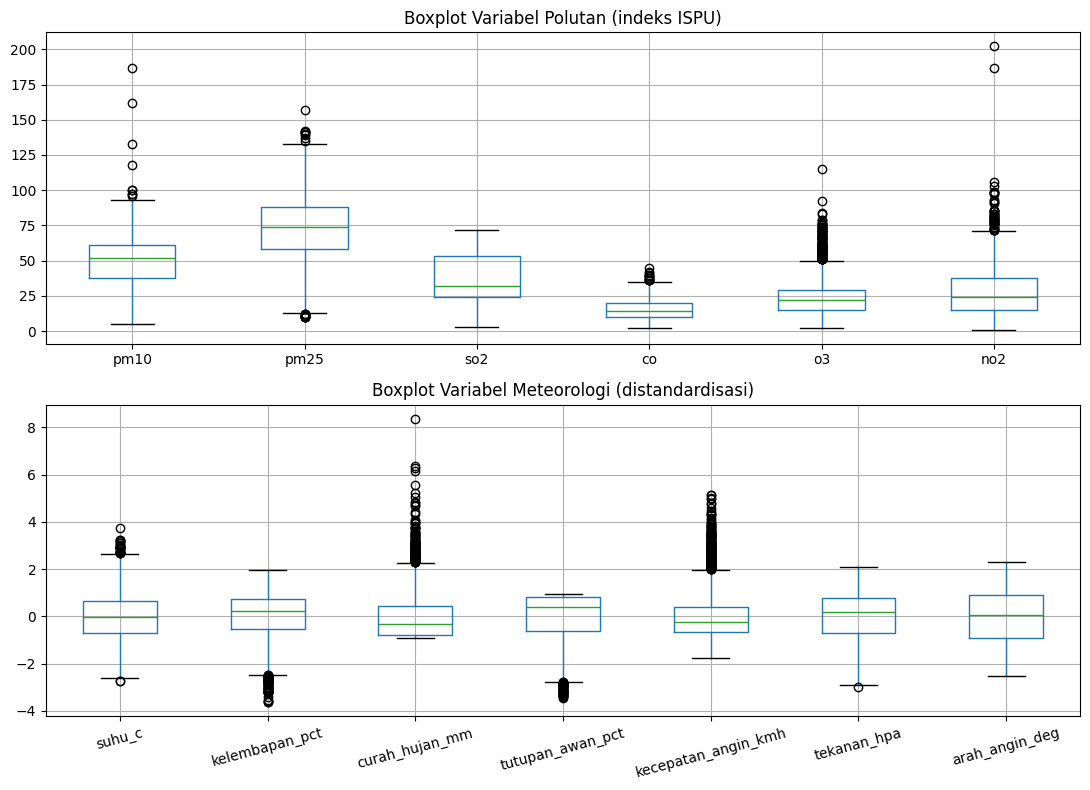


=== TABEL MISSING VALUE ===
Variabel  Jumlah_Kosong  Persen  Gap_Terpanjang_Hari
    pm10            259    7.91                  106
    pm25             58    1.77                    4
     so2             53    1.62                    8
      co             45    1.37                    3
      o3             44    1.34                    3
     no2             57    1.74                    4

Missing per stasiun:
                    pm10  pm25  so2  co  o3  no2
stasiun                                         
DKI1 Bundaran HI       1     8    7   7   7    4
DKI2 Kelapa Gading   117     7    6   7   5   15
DKI3 Jagakarsa         9     6   13  10  12   14
DKI4 Lubang Buaya     52    18   16  18  16   17
DKI5 Kebon Jeruk      80    19   11   3   4    7

=== PERBANDINGAN METODE PENGISIAN (rata-rata 5 percobaan) ===
                                   MAE    RMSE
Interpolasi linear               5.422   7.535
Forward fill (hari sebelumnya)   6.635   9.283
Median                         

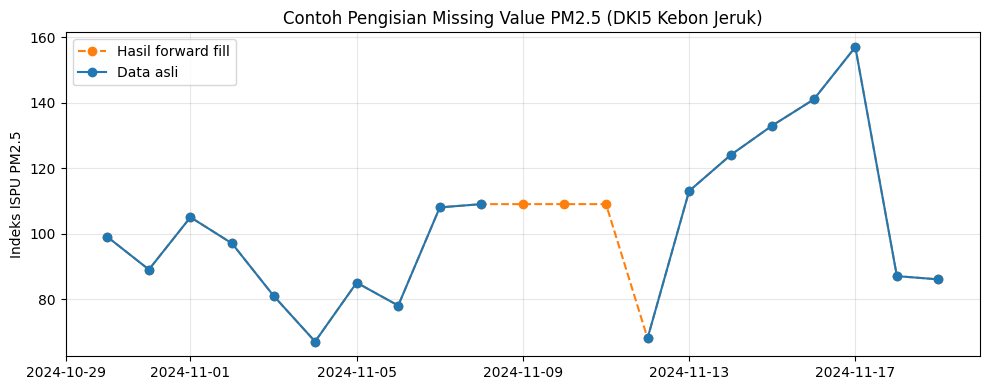

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 5. SIMPAN SEMUA TABEL
with pd.ExcelWriter('hasil_outlier_missing.xlsx') as w:
    tabel_outlier.to_excel(w, sheet_name='Outlier', index=False)
    tabel_missing.to_excel(w, sheet_name='Missing', index=False)
    tabel_metode.to_excel(w, sheet_name='Perbandingan_Metode')
    contoh.to_excel(w, sheet_name='Contoh_Pengisian')
for f in ['hasil_outlier_missing.xlsx', 'boxplot_outlier.png', 'contoh_pengisian.png']:
    files.download(f)

In [ ]:
# Mulai Training

!pip install -q xgboost==3.3.0 >/dev/null 2>&1
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, pickle, json
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy import stats
import xgboost as xgb
warnings.filterwarnings('ignore'); np.random.seed(42)
print("xgboost", xgb.__version__)

In [ ]:
# 1. MUAT DATA
from google.colab import files
up = files.upload()
df = pd.read_excel(list(up.keys())[0])
df['tanggal'] = pd.to_datetime(df['tanggal'])
print("Ukuran awal:", df.shape)

print("\n=== CEK VARIABEL STATIS PER TAHUN ===")
print(df.groupby(['stasiun', df['tanggal'].dt.year])[['kepadatan_penduduk_jiwa_km2','luas_rth_km2']].first())


In [ ]:
# 2. BUANG KOLOM DATA LEAKAGE (turunan dari PM2.5)
df = df.drop(columns=[c for c in ['max','parameter_kritis','kategori'] if c in df.columns])
df = df.sort_values(['stasiun','tanggal']).reset_index(drop=True)

# tandai baris yang PM2.5-nya asli (bukan hasil pengisian) -> metrik hanya di nilai asli
df['pm25_asli'] = df['pm25'].notna()
pol = ['pm10','pm25','so2','co','o3','no2']
df[pol] = df.groupby('stasiun')[pol].transform(lambda s: s.ffill(limit=7))

In [ ]:
# 3. FEATURE ENGINEERING (lag PM2.5 3 hari + rolling + waktu)
g = df.groupby('stasiun')
for lg in [1,2,3]:
    df[f'pm25_lag{lg}'] = g['pm25'].shift(lg)
df['pm25_roll3'] = g['pm25'].transform(lambda s: s.shift(1).rolling(3).mean())
df['bulan'] = df['tanggal'].dt.month
df['hari']  = df['tanggal'].dt.dayofweek


In [ ]:
# 4. TARGET 7 HORIZON
g = df.groupby('stasiun')
for h in [1,2,3,4,5,6,7]:
    df[f'target_h{h}']      = g['pm25'].shift(-h)
    df[f'target_h{h}_asli'] = g['pm25_asli'].shift(-h)

FITUR = ['kepadatan_penduduk_jiwa_km2','luas_rth_km2',
         'suhu_c','kelembapan_pct','curah_hujan_mm','tutupan_awan_pct',
         'kecepatan_angin_kmh','tekanan_hpa','arah_angin_deg',
         'pm10','pm25','so2','co','o3','no2',
         'pm25_lag1','pm25_lag2','pm25_lag3','pm25_roll3','bulan','hari']
NOVELTY = ['kepadatan_penduduk_jiwa_km2','luas_rth_km2']

df = df.dropna(subset=['pm25_lag1','pm25_lag2','pm25_lag3','pm25_roll3',
                       'target_h1','target_h2','target_h3',
                       'target_h4','target_h5','target_h6','target_h7']).reset_index(drop=True)
for h in [1,2,3,4,5,6,7]:
    df[f'target_h{h}_asli'] = df[f'target_h{h}_asli'].fillna(False).astype(bool)
print("Baris siap model:", len(df), "(harus 3225) | jumlah fitur:", len(FITUR))

In [ ]:
# 5. SPLIT KRONOLOGIS 70 / 15 / 15
tu = np.sort(df['tanggal'].unique()); n = len(tu)
batas_latih, batas_val = tu[int(n*0.70)], tu[int(n*0.85)]
m_tr = df['tanggal'] <  batas_latih
m_va = (df['tanggal'] >= batas_latih) & (df['tanggal'] < batas_val)
m_te = df['tanggal'] >= batas_val
print(f"Train {m_tr.sum()} | Val {m_va.sum()} | Test {m_te.sum()}")

def metrik(y_true, y_pred, asli):
    yt = np.asarray(y_true, float)[asli]; yp = np.asarray(y_pred, float)[asli]
    v = yt != 0
    return dict(MAE=mean_absolute_error(yt,yp),
                RMSE=np.sqrt(mean_squared_error(yt,yp)),
                MAPE=np.mean(np.abs((yt[v]-yp[v])/yt[v]))*100,
                R2=r2_score(yt,yp))

def latih(cols, h, params):
    scl = StandardScaler().fit(df.loc[m_tr, cols])
    Xtr, Xva, Xte = scl.transform(df.loc[m_tr,cols]), scl.transform(df.loc[m_va,cols]), scl.transform(df.loc[m_te,cols])
    ytr, yva, yte = df.loc[m_tr,f'target_h{h}'], df.loc[m_va,f'target_h{h}'], df.loc[m_te,f'target_h{h}']
    m = xgb.XGBRegressor(random_state=42, n_jobs=-1, early_stopping_rounds=50, eval_metric='rmse', **params)
    m.fit(Xtr, ytr, eval_set=[(Xva,yva)], verbose=False)
    a = df.loc[m_te,f'target_h{h}_asli'].values.astype(bool)
    pred = m.predict(Xte)
    return m, scl, metrik(yte, pred, a), pred

In [ ]:
# 6. BASELINE (parameter default) per horizon
DEF = dict(n_estimators=600, max_depth=6, learning_rate=0.3,
           subsample=1.0, colsample_bytree=1.0,
           min_child_weight=1, reg_alpha=0.0, reg_lambda=1.0)
print("\n=== BASELINE per horizon ===")
base = {}
for h in [1,2,3,4,5,6,7]:
    _,_,r,_ = latih(FITUR, h, DEF); base[h]=r
    print(f"t+{h}: MAE={r['MAE']:.3f} RMSE={r['RMSE']:.3f} MAPE={r['MAPE']:.2f}% R2={r['R2']:.3f}")

In [ ]:
# 7. OPTIMASI PSO
#    - 20 partikel x 40 iterasi
#    - inertia weight w menurun linear 0.9 -> 0.4 (kurangi collapse dini)
BB = np.array([3, 0.01, 0.50, 0.50, 1, 0.00, 0.50])    # batas bawah
BA = np.array([10, 0.30, 1.00, 1.00, 10, 2.00, 5.00])  # batas atas
def dekode(p):
    return dict(max_depth=int(round(p[0])), learning_rate=float(p[1]),
                subsample=float(p[2]), colsample_bytree=float(p[3]),
                min_child_weight=int(round(p[4])), reg_alpha=float(p[5]),
                reg_lambda=float(p[6]), n_estimators=600)

scl1 = StandardScaler().fit(df.loc[m_tr, FITUR])
Xtr1, Xva1 = scl1.transform(df.loc[m_tr,FITUR]), scl1.transform(df.loc[m_va,FITUR])
ytr1, yva1 = df.loc[m_tr,'target_h1'], df.loc[m_va,'target_h1']
cache = {}
def fitness(p):
    pr = dekode(p); key = tuple(round(v,4) if isinstance(v,float) else v for v in pr.values())
    if key in cache: return cache[key]
    m = xgb.XGBRegressor(random_state=42, n_jobs=-1, early_stopping_rounds=50, eval_metric='rmse', **pr)
    m.fit(Xtr1, ytr1, eval_set=[(Xva1,yva1)], verbose=False)
    r = np.sqrt(mean_squared_error(yva1, m.predict(Xva1))); cache[key]=r; return r

rng = np.random.default_rng(42)
N_PARTIKEL, N_ITERASI = 20, 40
w_awal, w_akhir, c1, c2 = 0.9, 0.4, 1.5, 1.5
rentang = BA - BB
pos = BB + rng.random((N_PARTIKEL,7))*rentang
vmax = 0.5*rentang
vel = rng.uniform(-1,1,(N_PARTIKEL,7))*vmax
skor = np.array([fitness(p) for p in pos])
pbest, pbs = pos.copy(), skor.copy()
gi = int(np.argmin(pbs)); gbest = pbest[gi].copy(); gbs = float(pbs[gi])
riwayat = [gbs]
print(f"\n=== PSO ===\nIter  0 | gbest RMSE(val) = {gbs:.4f}")
for it in range(1, N_ITERASI+1):
    w = w_awal - (w_awal - w_akhir) * it / N_ITERASI
    for i in range(N_PARTIKEL):
        r1, r2 = rng.random(7), rng.random(7)
        vel[i] = np.clip(w*vel[i] + c1*r1*(pbest[i]-pos[i]) + c2*r2*(gbest-pos[i]), -vmax, vmax)
        pos[i] = np.clip(pos[i]+vel[i], BB, BA)
        s = fitness(pos[i])
        if s < pbs[i]:
            pbs[i], pbest[i] = s, pos[i].copy()
            if s < gbs: gbs, gbest = float(s), pos[i].copy()
    riwayat.append(gbs)
    print(f"Iter {it:2d} | w={w:.3f} | gbest RMSE(val) = {gbs:.4f}")
BEST = dekode(gbest)
print("\nHyperparameter terbaik:", {k:(round(v,4) if isinstance(v,float) else v) for k,v in BEST.items()})

plt.figure(figsize=(7,4))
plt.plot(range(len(riwayat)), riwayat, marker='o')
plt.xlabel('Iterasi'); plt.ylabel('RMSE validasi (gbest)')
plt.title('Kurva Konvergensi PSO'); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

In [ ]:
# 8. MODEL FINAL (XGBoost + PSO) per horizon
print("\n=== XGBoost + PSO per horizon ===")
pso = {}
for h in [1,2,3,4,5,6,7]:
    m, scl, r, _ = latih(FITUR, h, BEST); pso[h]=r
    with open(f'model_pm25_h{h}.pkl','wb') as f:
        pickle.dump({'model':m, 'scaler':scl, 'fitur':FITUR, 'horizon':h}, f)
    print(f"t+{h}: MAE={r['MAE']:.3f} RMSE={r['RMSE']:.3f} MAPE={r['MAPE']:.2f}% R2={r['R2']:.3f}  -> model_pm25_h{h}.pkl")

In [ ]:
# 9. TABEL RINGKAS Baseline vs PSO (semua horizon)
print("\n"+"="*64)
print(f"{'Horizon':9s}{'Model':10s}{'MAE':>9s}{'RMSE':>9s}{'MAPE':>9s}{'R2':>9s}")
print("="*64)
for h in [1,2,3,4,5,6,7]:
    for nm, r in [('Baseline',base[h]),('XGB+PSO',pso[h])]:
        print(f"{'t+'+str(h):9s}{nm:10s}{r['MAE']:9.3f}{r['RMSE']:9.3f}{r['MAPE']:8.2f}%{r['R2']:9.3f}")

In [ ]:
# 10. SKENARIO S1/S2/S3
df = pd.concat([df, pd.get_dummies(df['stasiun'], prefix='st').astype(int)], axis=1)
ST = [c for c in df.columns if c.startswith('st_')]
DASAR = [c for c in FITUR if c not in NOVELTY]
def dm_test(y, p1, p2, h=1):
    e1, e2 = y-p1, y-p2; d = e1**2 - e2**2; nT=len(d); g0=np.var(d,ddof=0)
    gm=[np.cov(d[k:],d[:-k])[0,1] for k in range(1,h)] if h>1 else []
    vd=(g0+2*sum(gm))/nT
    if vd<=0: return np.nan, np.nan
    s=np.mean(d)/np.sqrt(vd); return s, 2*(1-stats.t.cdf(abs(s),nT-1))

print("\n=== S1/S2/S3 + Diebold-Mariano (S1 vs S3) ===")
for h in [1,2,3,4,5,6,7]:
    _,_,r1,p1 = latih(DASAR,     h, BEST)
    _,_,r2,_  = latih(DASAR+ST,  h, BEST)
    _,_,r3,p3 = latih(DASAR+NOVELTY, h, BEST)
    a = df.loc[m_te,f'target_h{h}_asli'].values.astype(bool)
    yt = df.loc[m_te,f'target_h{h}'].values[a]
    s, pv = dm_test(yt, p1[a], p3[a], h)
    tanda = 'SIGNIFIKAN' if (not np.isnan(pv) and pv<0.05) else 'tidak signifikan'
    print(f"t+{h}: S1={r1['RMSE']:.3f}  S2(+stasiun)={r2['RMSE']:.3f}  S3(+novelty)={r3['RMSE']:.3f} "
          f"| DM={s:.3f} p={pv:.4f} ({tanda})")

In [ ]:
# 11. FEATURE IMPORTANCE
m1, scl1b, _, _ = latih(FITUR, 1, BEST)
imp = pd.Series(m1.feature_importances_, index=FITUR).sort_values()
plt.figure(figsize=(8,7)); imp.plot(kind='barh')
plt.title('Feature Importance (XGBoost + PSO, t+1)'); plt.xlabel('Importance')
plt.tight_layout(); plt.show()
print("\nPeringkat novelty (t+1):")
imp_desc = imp.sort_values(ascending=False)
for f in NOVELTY:
    print(f"  {f}: peringkat {list(imp_desc.index).index(f)+1} dari {len(FITUR)}")

In [ ]:
# 12. BASELINE PERSISTENCE
print("\n=== BASELINE PERSISTENCE (naif) vs XGB+PSO ===")
pm_te_hari_ini = df.loc[m_te, 'pm25'].values
persist = {}
for h in [1,2,3,4,5,6,7]:
    a  = df.loc[m_te, f'target_h{h}_asli'].values.astype(bool)
    yt = df.loc[m_te, f'target_h{h}'].values
    r  = metrik(yt, pm_te_hari_ini, a)
    persist[h] = r
    menang = "menang" if pso[h]['RMSE'] < r['RMSE'] else "KALAH"
    print(f"t+{h}: Persistence RMSE={r['RMSE']:.3f} R2={r['R2']:.3f}  |  "
          f"XGB+PSO RMSE={pso[h]['RMSE']:.3f} R2={pso[h]['R2']:.3f}  ({menang})")

In [ ]:
# 13. UJI KESTABILAN MULTI-SEED
SEEDS = [42, 1, 7, 123, 2024]
def latih_seed(cols, h, params, seed):
    p = dict(params); p['random_state'] = seed
    scl = StandardScaler().fit(df.loc[m_tr, cols])
    Xtr, Xva, Xte = scl.transform(df.loc[m_tr,cols]), scl.transform(df.loc[m_va,cols]), scl.transform(df.loc[m_te,cols])
    ytr, yva, yte = df.loc[m_tr,f'target_h{h}'], df.loc[m_va,f'target_h{h}'], df.loc[m_te,f'target_h{h}']
    m = xgb.XGBRegressor(n_jobs=-1, early_stopping_rounds=50, eval_metric='rmse', **p)
    m.fit(Xtr, ytr, eval_set=[(Xva,yva)], verbose=False)
    a = df.loc[m_te,f'target_h{h}_asli'].values.astype(bool)
    return metrik(yte, m.predict(Xte), a)

print(f"\n=== KESTABILAN MULTI-SEED (XGB+PSO, {len(SEEDS)} seed) ===")
print(f"{'Horizon':9s}{'RMSE (mean±std)':>20s}{'R2 (mean±std)':>20s}")
for h in [1,2,3,4,5,6,7]:
    res   = [latih_seed(FITUR, h, BEST, s) for s in SEEDS]
    rmses = [x['RMSE'] for x in res]; r2s = [x['R2'] for x in res]
    print(f"{'t+'+str(h):9s}{np.mean(rmses):8.3f} ± {np.std(rmses):.3f}   {np.mean(r2s):8.3f} ± {np.std(r2s):.3f}")

In [ ]:
# 14. PEMBANDING: RANDOM SEARCH (budget evaluasi SAMA dengan PSO)
N_EVAL_RS = N_PARTIKEL * (N_ITERASI + 1)
rng_rs = np.random.default_rng(42)

best_rs, best_rs_skor = None, np.inf
riwayat_rs = []
print(f"\n=== RANDOM SEARCH ({N_EVAL_RS} evaluasi) ===")
for i in range(N_EVAL_RS):
    p = BB + rng_rs.random(7) * rentang
    s = fitness(p)
    if s < best_rs_skor:
        best_rs_skor, best_rs = s, p.copy()
    if (i + 1) % N_PARTIKEL == 0:
        riwayat_rs.append(best_rs_skor)
BEST_RS = dekode(best_rs)
print(f"RMSE(val) terbaik RS = {best_rs_skor:.4f} | PSO = {gbs:.4f}")
print("Hyperparameter RS:", {k:(round(v,4) if isinstance(v,float) else v) for k,v in BEST_RS.items()})

# kurva konvergensi PSO vs RS (budget setara)
plt.figure(figsize=(7,4))
plt.plot(range(len(riwayat)), riwayat, marker='o', label='PSO')
plt.plot(range(len(riwayat_rs)), riwayat_rs, marker='s', label='Random Search')
plt.xlabel(f'Iterasi (1 iterasi = {N_PARTIKEL} evaluasi)'); plt.ylabel('RMSE validasi terbaik')
plt.title('Konvergensi PSO vs Random Search'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

# evaluasi di data uji per horizon + DM test (RS vs PSO)
print("\n" + "="*72)
print(f"{'Horizon':9s}{'Model':10s}{'MAE':>9s}{'RMSE':>9s}{'MAPE':>9s}{'R2':>9s}")
print("="*72)
rs = {}
for h in [1,2,3,4,5,6,7]:
    _,_,r_rs,p_rs  = latih(FITUR, h, BEST_RS); rs[h] = r_rs
    _,_,_,  p_pso  = latih(FITUR, h, BEST)
    for nm, r in [('Default',base[h]), ('RandomS',r_rs), ('PSO',pso[h])]:
        print(f"{'t+'+str(h):9s}{nm:10s}{r['MAE']:9.3f}{r['RMSE']:9.3f}{r['MAPE']:8.2f}%{r['R2']:9.3f}")
    a  = df.loc[m_te, f'target_h{h}_asli'].values.astype(bool)
    yt = df.loc[m_te, f'target_h{h}'].values[a]
    s, pv = dm_test(yt, p_rs[a], p_pso[a], h)
    arah = 'PSO lebih baik' if s > 0 else 'RS lebih baik'
    sig  = 'SIGNIFIKAN' if (not np.isnan(pv) and pv < 0.05) else 'tidak signifikan'
    print(f"{'':9s}DM RS vs PSO = {s:.3f}, p = {pv:.4f} ({arah}, {sig})")
    print("-"*72)

xgboost 3.3.0


Saving datasetskripsi.xlsx to datasetskripsi.xlsx
Ukuran awal: (3275, 19)

=== CEK VARIABEL STATIS PER TAHUN ===
                            kepadatan_penduduk_jiwa_km2  luas_rth_km2
stasiun            tanggal                                           
DKI1 Bundaran HI   2024                           13019         0.272
                   2025                           12959         0.273
DKI2 Kelapa Gading 2024                            9111         0.204
                   2025                            9111         0.204
DKI3 Jagakarsa     2024                           15160         1.088
                   2025                           15160         1.121
DKI4 Lubang Buaya  2024                           10791         1.573
                   2025                           10718         1.677
DKI5 Kebon Jeruk   2024                           20169         0.209
                   2025                           20328         0.210
Baris siap model: 3225 (harus 3225) | jumlah fi

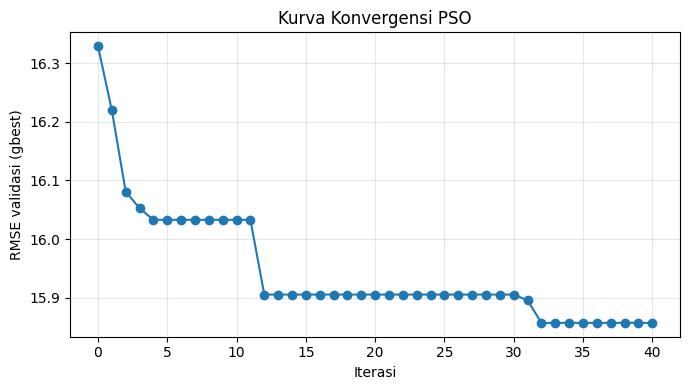


=== XGBoost + PSO per horizon ===
t+1: MAE=9.841 RMSE=12.522 MAPE=12.60% R2=0.283  -> model_pm25_h1.pkl
t+2: MAE=11.386 RMSE=14.318 MAPE=14.55% R2=0.058  -> model_pm25_h2.pkl
t+3: MAE=11.230 RMSE=14.190 MAPE=14.68% R2=0.075  -> model_pm25_h3.pkl
t+4: MAE=11.524 RMSE=14.505 MAPE=15.04% R2=0.042  -> model_pm25_h4.pkl
t+5: MAE=11.692 RMSE=14.811 MAPE=15.47% R2=0.078  -> model_pm25_h5.pkl
t+6: MAE=11.688 RMSE=14.692 MAPE=15.78% R2=0.128  -> model_pm25_h6.pkl
t+7: MAE=11.509 RMSE=14.430 MAPE=16.28% R2=0.212  -> model_pm25_h7.pkl

Horizon  Model           MAE     RMSE     MAPE       R2
t+1      Baseline     10.459   13.486   13.34%    0.168
t+1      XGB+PSO       9.841   12.522   12.60%    0.283
t+2      Baseline     12.378   15.725   15.78%   -0.136
t+2      XGB+PSO      11.386   14.318   14.55%    0.058
t+3      Baseline     13.004   16.374   16.83%   -0.232
t+3      XGB+PSO      11.230   14.190   14.68%    0.075
t+4      Baseline     12.643   15.923   16.25%   -0.154
t+4      XGB+PSO    

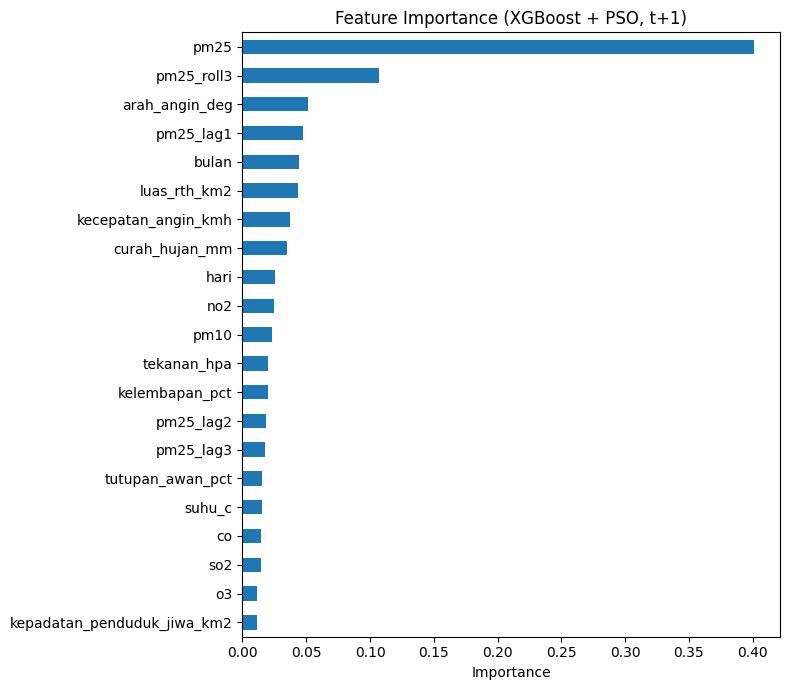


Peringkat novelty (t+1):
  kepadatan_penduduk_jiwa_km2: peringkat 21 dari 21
  luas_rth_km2: peringkat 6 dari 21

=== BASELINE PERSISTENCE (naif) vs XGB+PSO ===
t+1: Persistence RMSE=15.109 R2=-0.044  |  XGB+PSO RMSE=12.522 R2=0.283  (menang)
t+2: Persistence RMSE=16.557 R2=-0.259  |  XGB+PSO RMSE=14.318 R2=0.058  (menang)
t+3: Persistence RMSE=17.688 R2=-0.438  |  XGB+PSO RMSE=14.190 R2=0.075  (menang)
t+4: Persistence RMSE=18.677 R2=-0.588  |  XGB+PSO RMSE=14.505 R2=0.042  (menang)
t+5: Persistence RMSE=18.433 R2=-0.429  |  XGB+PSO RMSE=14.811 R2=0.078  (menang)
t+6: Persistence RMSE=19.160 R2=-0.483  |  XGB+PSO RMSE=14.692 R2=0.128  (menang)
t+7: Persistence RMSE=18.634 R2=-0.314  |  XGB+PSO RMSE=14.430 R2=0.212  (menang)

=== KESTABILAN MULTI-SEED (XGB+PSO, 5 seed) ===
Horizon       RMSE (mean±std)       R2 (mean±std)
t+1        12.550 ± 0.143      0.280 ± 0.017
t+2        14.163 ± 0.090      0.079 ± 0.012
t+3        14.096 ± 0.068      0.087 ± 0.009
t+4        14.693 ± 0.114     

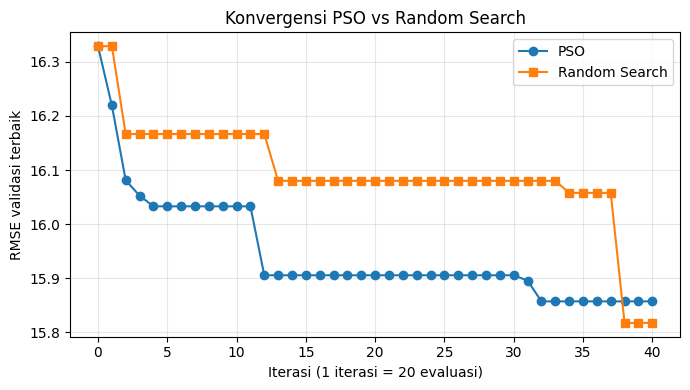


Horizon  Model           MAE     RMSE     MAPE       R2
t+1      Default      10.459   13.486   13.34%    0.168
t+1      RandomS       9.929   12.796   12.97%    0.251
t+1      PSO           9.841   12.522   12.60%    0.283
         DM RS vs PSO = 1.398, p = 0.1629 (PSO lebih baik, tidak signifikan)
------------------------------------------------------------------------
t+2      Default      12.378   15.725   15.78%   -0.136
t+2      RandomS      11.570   14.460   15.25%    0.040
t+2      PSO          11.386   14.318   14.55%    0.058
         DM RS vs PSO = 0.464, p = 0.6431 (PSO lebih baik, tidak signifikan)
------------------------------------------------------------------------
t+3      Default      13.004   16.374   16.83%   -0.232
t+3      RandomS      11.360   14.311   14.92%    0.059
t+3      PSO          11.230   14.190   14.68%    0.075
         DM RS vs PSO = 0.540, p = 0.5895 (PSO lebih baik, tidak signifikan)
--------------------------------------------------------------

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


SELESAI. Tersimpan: model_pm25_h1.pkl ... model_pm25_h7.pkl + hasil_evaluasi.json


In [ ]:
# 15. SIMPAN HASIL EVALUASI + UNDUH SEMUA FILE
with open('hasil_evaluasi.json','w') as f:
    json.dump({'default':base, 'random_search':rs, 'pso':pso, 'persistence':persist,
               'best_pso':BEST, 'best_rs':BEST_RS}, f, indent=2, default=float)

from google.colab import files
for h in [1,2,3,4,5,6,7]: files.download(f'model_pm25_h{h}.pkl')
files.download('hasil_evaluasi.json')
print("\nSELESAI. Tersimpan: model_pm25_h1.pkl ... model_pm25_h7.pkl + hasil_evaluasi.json")

In [ ]:
import sklearn, numpy; print(sklearn.__version__, numpy.__version__)

1.6.1 2.1.3
